# Heart Disease Prediction - A Complete Machine Learning Project
## From data loading to model validation

**Dataset:** Heart Failure Prediction Dataset (fedesoriano, Kaggle) - `heart.csv`, 918 patients, 11 clinical features + 1 target

**Objective:** Build, validate and package a supervised classification model that predicts whether a patient has heart disease, following the method from the course *"Construire un projet de Machine Learning"*.

### Author

- **Author**: Ange Maxime TCHOUTANG
- **Author's Contact Info**:\
[Email](mailto:maxime.tchoutang@facsciences-uy1.cm)\
[Github](https://github.com/AngeMaxime)\
[Linkedin](https://www.linkedin.com/in/%F0%9F%A7%ACtchoutang-ange-maxime-834b6729a/)\
[twitter](https://x.com/AngeTchoutang)

### How this notebook maps to the course (the 9 steps of an ML project)

| # | Course step | Section of this notebook |
|---|---|---|
| 1 | Define the problem | [1. Problem definition](#sec1) |
| – | Environment & imports | [2. Environment & imports](#sec2) |
| 2 | Understand the data | [3. Data import](#sec3) and [4. Understanding the data](#sec4) |
| – | EDA (no data modification) | [5. Exploratory Data Analysis](#sec5) |
| 3 | Clean the data | [6. Data diagnostics & cleaning](#sec6) |
| 4 | Split into train / test | [7. Train / test split](#sec7) |
| 5 | Feature engineering | [8. Feature engineering & preprocessing](#sec8) and [9. Feature selection](#sec9) |
| 6 | Choose the model | [10. Model choice](#sec10) |
| 7 | Train the model | [11. Baseline training & cross-validation](#sec11) and [12. Hyperparameter tuning](#sec12) |
| 8 | Evaluate on independent data | [13. Final evaluation on the test set](#sec13) and [14. Additional validation](#sec14) |
| 9 | Implementation / deployment | [15. Packaging & pre-deployment tests](#sec15) |
| – | Wrap-up | [16. Conclusion & checklist](#sec16) |

### Golden rules applied throughout

1. **Split before you learn anything from the data.** Every statistic that is *learned* (imputation values, scaling parameters, encodings, feature selection) is computed on the **train set only**.
2. **The test set is used once**, at the end, to evaluate the model that was chosen using cross-validation on the train set.
3. **Start simple** (baseline → logistic regression), then add complexity only if it pays off.
4. **Never rely on a single number**: several metrics, several models, same test data.

<a id="sec1"></a>
## 1. Problem definition  *(course step 1)*

Before touching the data, we restate the problem, the objective guides every later decision.

**Business / clinical question.** Given a patient's routine clinical measurements (age, sex, chest-pain type, blood pressure, cholesterol, ECG results, exercise test results…), can we predict whether the patient has heart disease?

**Type of problem.**
- *Prediction*, not only description → we build a model.
- *Supervised* learning (the data contains the answer, `HeartDisease`).
- The target is *categorical and binary* (1 = heart disease, 0 = normal) → **binary classification**.

**Context and existing work.** The dataset combines five public heart-disease datasets (Cleveland, Hungarian, Switzerland, Long Beach VA, Stalog) and is among the most used benchmarks for tabular classification. Public notebooks on it typically report accuracies roughly in the mid-80s to ~90 % — a reference range to sanity-check our results against, **not** a target to chase. Our own earlier work (Week 2 – feature engineering, Week 3 – advanced analysis) is the starting point, with one methodological correction explained in section 6.

**Which metric matters?** The cost of an error is not symmetric:

| Error | Meaning | Consequence |
|---|---|---|
| False negative | A sick patient is classified as healthy | Missed diagnosis → **most costly** |
| False positive | A healthy patient is classified as sick | Extra tests, anxiety → costly but recoverable |

We therefore monitor **recall (sensitivity)** closely, together with **precision, F1, ROC-AUC and accuracy**. Model *selection* uses ROC-AUC (threshold-independent); the *decision threshold* is discussed separately in section 14.

**Constraints and caveats.**
- Small sample (918 rows) → results have uncertainty; we quantify it (cross-validation, bootstrap).
- Data merged from several hospitals → heterogeneity in measurement practice (see the zero cholesterol values).
- This is a **decision-support** exercise, not a certified medical device.

<a id="sec2"></a>
## 2. Environment & imports

**Good practice:** work in a dedicated virtual environment (venv or conda) so the project has its own library versions, and export them (`pip freeze > requirements.txt`). The cell at the end of this notebook prints the exact versions used.

```bash
python -m venv heart-env
heart-env\Scripts\activate          # Windows   (source heart-env/bin/activate on Linux/macOS)
pip install pandas numpy matplotlib seaborn scipy scikit-learn joblib jupyter
pip install xgboost                  # optional: one extra model in the comparison
```

All libraries are imported **once, here**, and not re-imported in later sections.

In [1]:
# ---- Core libraries
import warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ---- scikit-learn
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV,
                                     RandomizedSearchCV, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
import joblib

# ---- Optional: XGBoost (the notebook still runs without it)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)

# ---- Project constants
RANDOM_STATE = 42          # reproducibility
TARGET       = "HeartDisease"
TEST_SIZE    = 0.20        # see section 7 for the justification
DATA_PATH    = Path("heart.csv")   # <-- change to your own path, e.g. Path(r"C:\Users\Ange\...\heart.csv")

print("Libraries loaded. XGBoost available:", HAS_XGB)

Libraries loaded. XGBoost available: False


<a id="sec3"></a>
## 3. Data import  *(course step 2, section a of the code organisation)*

We import the raw data and immediately check shape and **data types** (strings vs numbers). No modification is made here.

In [3]:
df_raw = pd.read_csv(r"D:\mon PC\Trianing complet   Data Science et Bio-informatic\scripts\ML scripts\analysis\Data\heart.csv")
print(f"Dataset shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
df_raw.head(10)

Dataset shape: 918 rows x 12 columns


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [4]:
df_raw.dtypes.to_frame("dtype").T

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
dtype,int64,object,object,int64,int64,int64,object,int64,object,float64,object,int64


<a id="sec4"></a>
## 4. Understanding the data  *(course step 2)*

Questions to answer before any analysis: *Where does the data come from? What does each column mean? What is the target? Is the data sufficient and appropriate for the question?*

**Source:** Heart Failure Prediction Dataset (fedesoriano, Kaggle). 918 patients after removal of duplicates across the five original datasets. One row = one patient.

| Column | Type | Meaning |
|---|---|---|
| `Age` | numeric | Age of the patient (years) |
| `Sex` | binary categorical | M = male, F = female |
| `ChestPainType` | nominal categorical | TA = typical angina, ATA = atypical angina, NAP = non-anginal pain, ASY = asymptomatic |
| `RestingBP` | numeric | Resting blood pressure (mm Hg) |
| `Cholesterol` | numeric | Serum cholesterol (mg/dl) |
| `FastingBS` | binary (0/1) | 1 if fasting blood sugar > 120 mg/dl, else 0 |
| `RestingECG` | nominal categorical | Normal, ST (ST-T wave abnormality), LVH (left ventricular hypertrophy) |
| `MaxHR` | numeric | Maximum heart rate achieved during the exercise test |
| `ExerciseAngina` | binary categorical | Y/N — exercise-induced angina |
| `Oldpeak` | numeric | ST depression induced by exercise relative to rest |
| `ST_Slope` | ordinal categorical | Slope of the peak-exercise ST segment: Up, Flat, Down |
| **`HeartDisease`** | **binary target** | **1 = heart disease, 0 = normal** |

In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [6]:
# First look: head / tail / random sample
display(df_raw.tail(5))
display(df_raw.sample(5, random_state=RANDOM_STATE))

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1
917,38,M,NAP,138,175,0,Normal,173,N,0.0,Up,0


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
668,63,F,ATA,140,195,0,Normal,179,N,0.0,Up,0
30,53,M,NAP,145,518,0,Normal,130,N,0.0,Flat,1
377,65,M,ASY,160,0,1,ST,122,N,1.2,Flat,1
535,56,M,ASY,130,0,0,LVH,122,Y,1.0,Flat,1
807,54,M,ATA,108,309,0,Normal,156,N,0.0,Up,0


In [7]:
# Numerical summary and categorical (text) variables
display(df_raw.describe().T)
print("Text / categorical columns:", df_raw.select_dtypes(include=["object", "string"]).columns.tolist())
display(df_raw.describe(include=["object", "string"]).T)

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


Text / categorical columns: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


,count,unique,top,freq
Sex,918,2,M,725
ChestPainType,918,4,ASY,496
RestingECG,918,3,Normal,552
ExerciseAngina,918,2,N,547
ST_Slope,918,3,Flat,460


**Is the data suitable for the question?** 918 labelled patients, 11 clinically meaningful predictors, a binary target with no missing labels: yes, it is adequate for a first predictive model. Limits: the sample is small and merged from several sources, so we will favour simple, well-validated models and report uncertainty.

<a id="sec5"></a>
## 5. Exploratory Data Analysis  *(section b of the code organisation)*

> **Rule from the course: no data modification in this section.** We only look: distributions, relationships, correlations.
> (EDA on the full dataset is purely descriptive here; all *learned* transformations come after the train/test split.)

### 5.1 Target variable

,count,percent
HeartDisease,,
0,410,44.7
1,508,55.3


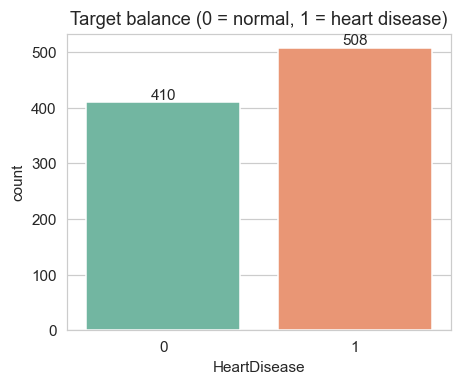

In [8]:
counts = df_raw[TARGET].value_counts().sort_index()
pct = df_raw[TARGET].value_counts(normalize=True).sort_index().mul(100).round(1)
display(pd.DataFrame({"count": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(data=df_raw, x=TARGET, hue=TARGET, palette="Set2", legend=False, ax=ax)
ax.set_title("Target balance (0 = normal, 1 = heart disease)")
for c in ax.containers: ax.bar_label(c)
plt.show()

The classes are reasonably balanced (≈ 55 % / 45 %), so no resampling is required; we will still use **stratified** splits so that every fold keeps this ratio.

**Reading:** 508 patients with heart disease (55.3 %) versus 410 without (44.7 %). A model that always answers "disease" would already be right 55 % of the time — this is the floor our models must clearly beat.

### 5.2 Univariate analysis - numerical variables

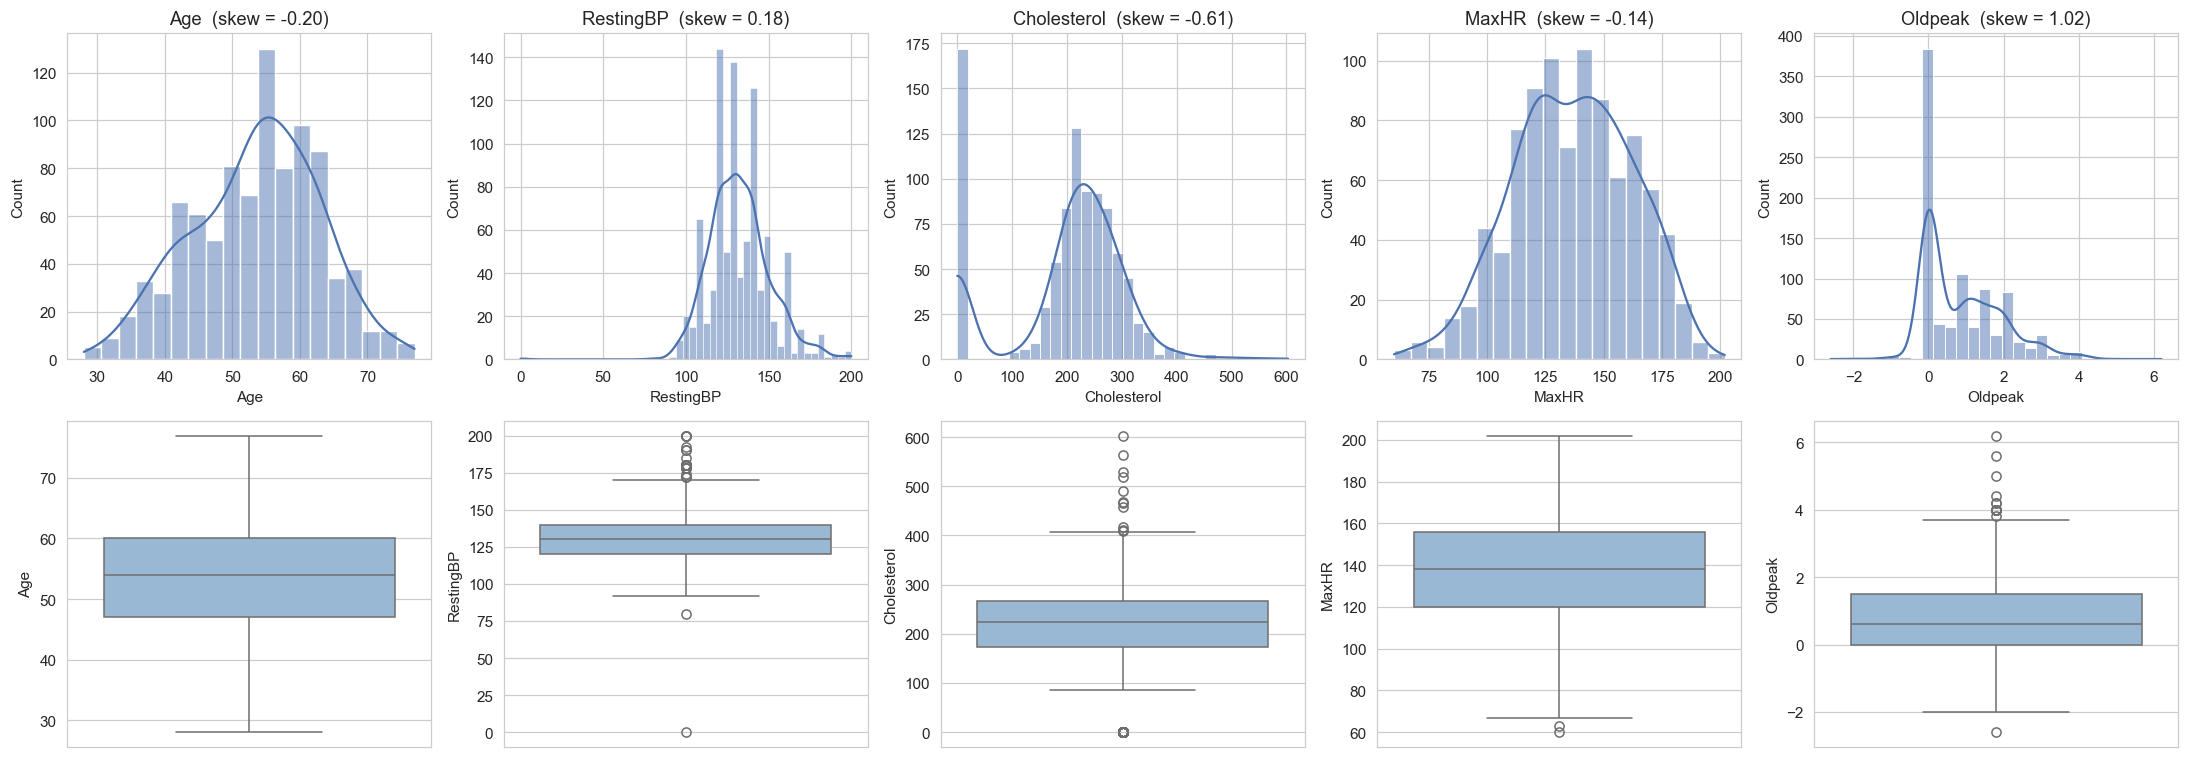

,mean,median,std,min,max,skew
Age,53.51,54.0,9.43,28.0,77.0,-0.20
RestingBP,132.40,130.0,18.51,0.0,200.0,0.18
Cholesterol,198.80,223.0,109.38,0.0,603.0,-0.61
MaxHR,136.81,138.0,25.46,60.0,202.0,-0.14
Oldpeak,0.89,0.6,1.07,-2.6,6.2,1.02


In [9]:
num_vars = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, col in enumerate(num_vars):
    sns.histplot(df_raw[col], kde=True, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"{col}  (skew = {df_raw[col].skew():.2f})")
    sns.boxplot(y=df_raw[col], ax=axes[1, i], color="#8FB8DE")
plt.tight_layout(); plt.show()

stats_tbl = df_raw[num_vars].agg(["mean", "median", "std", "min", "max", "skew"]).T.round(2)
stats_tbl

**Reading:**
- `Oldpeak` is clearly right-skewed (skew ≈ 1.0) with a spike at 0; `Cholesterol` is left-skewed because of a block of zeros (see section 6). `Age`, `MaxHR` and `RestingBP` are roughly symmetric.
- The boxplots show `Cholesterol` values at 0 and a `RestingBP` value of 0 : data-quality problems, not real measurements. A handful of very high cholesterol values (> 400 mg/dl, 13 patients) are plausible clinically and are kept; standardisation and tree/ensemble models cope with them.

### 5.3 Univariate and bivariate analysis, categorical variables

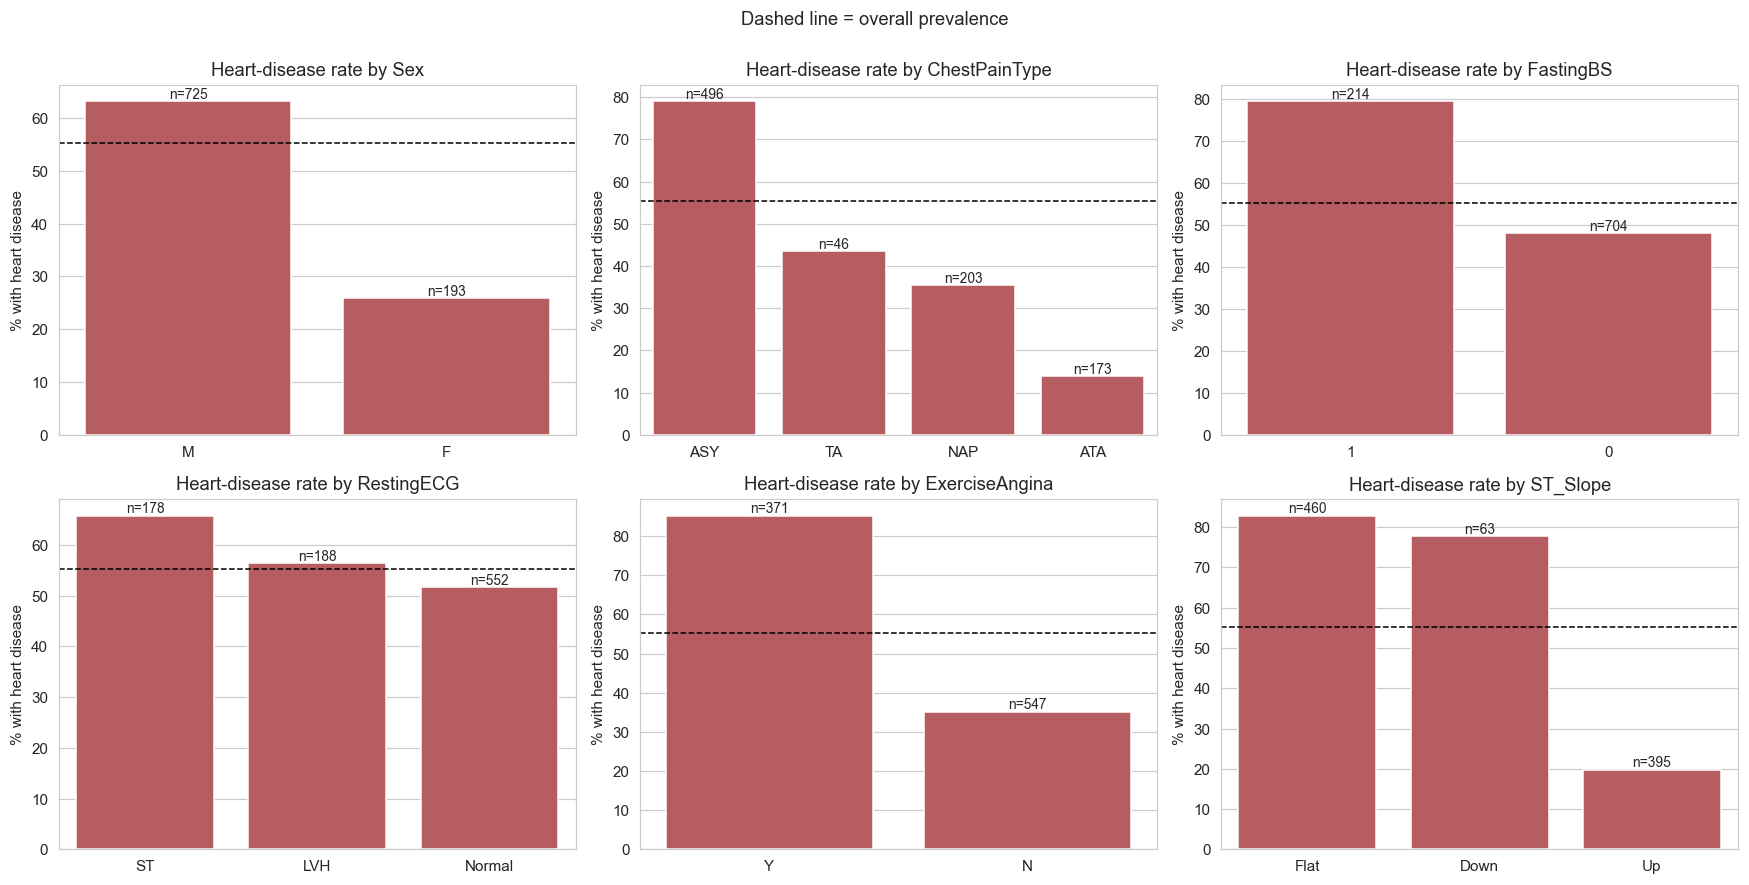

In [10]:
cat_vars = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_vars):
    rate = df_raw.groupby(col)[TARGET].mean().mul(100)
    n = df_raw[col].value_counts()
    order = rate.sort_values(ascending=False).index
    sns.barplot(x=[str(o) for o in order], y=rate[order].values, ax=ax, color="#C44E52")
    for p, lab in zip(ax.patches, order):
        ax.annotate(f"n={n[lab]}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.axhline(df_raw[TARGET].mean() * 100, ls="--", c="k", lw=1)
    ax.set_title(f"Heart-disease rate by {col}"); ax.set_ylabel("% with heart disease"); ax.set_xlabel("")
plt.suptitle("Dashed line = overall prevalence", y=1.0)
plt.tight_layout(); plt.show()

**Reading:** categorical variables separate the two groups strongly.
- `ChestPainType`: **asymptomatic (ASY)** patients have heart disease in 79 % of cases, versus 14 % for atypical angina (ATA), counter-intuitive but well known: silent disease is dangerous.
- `ExerciseAngina = Y`: 85 % vs 35 % for `N`.
- `ST_Slope`: Flat (83 %) and Down (78 %) versus Up (20 %).
- `Sex`: 63 % of men vs 26 % of women are positive — but women are only 193 of 918 patients (21 %), which matters for generalisation (section 14.5).
- `FastingBS = 1`: 79 % vs 48 %. `RestingECG` is the weakest signal (52–66 %).

### 5.4 Numerical variables vs target

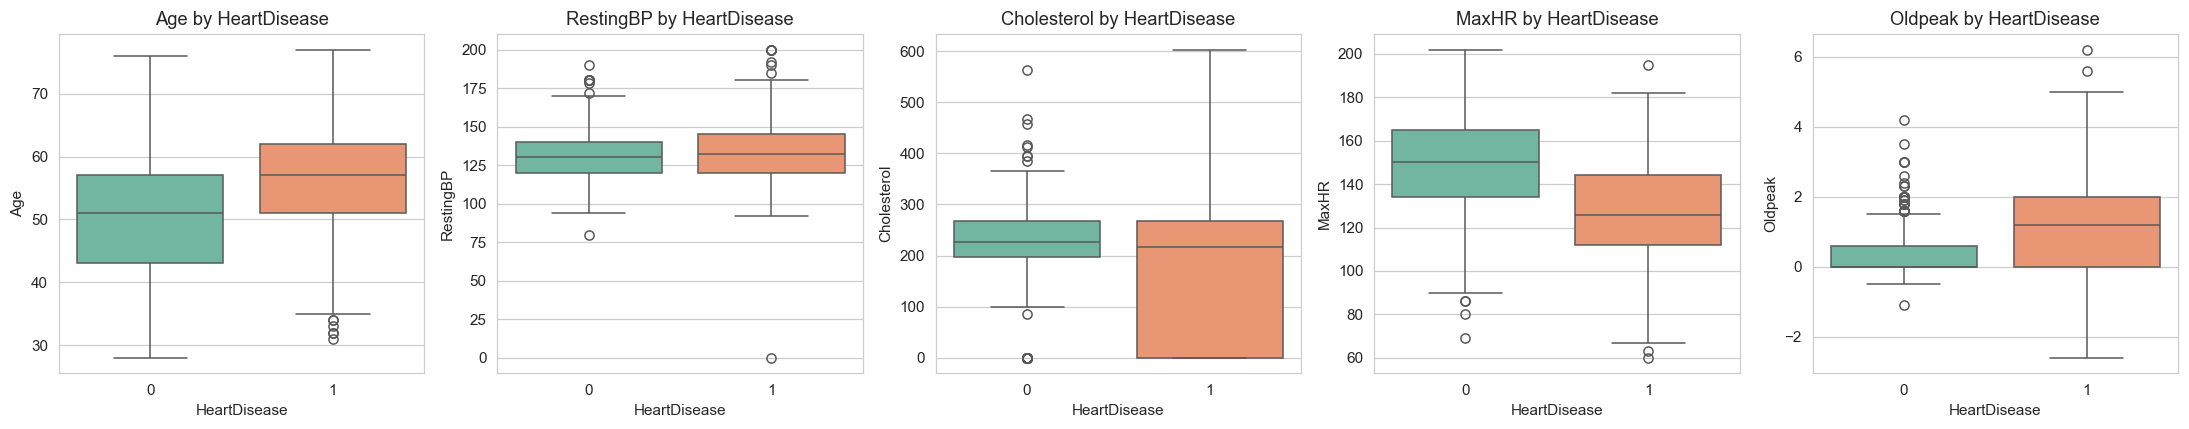

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, num_vars):
    sns.boxplot(data=df_raw, x=TARGET, y=col, hue=TARGET, palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} by {TARGET}")
plt.tight_layout(); plt.show()

**Reading:** patients with heart disease are older (median 57 vs 51 years), reach a **lower maximum heart rate** (126 vs 150 bpm) and have a **higher Oldpeak** (median 1.2 vs 0.0). Resting blood pressure barely differs between groups. `Cholesterol` looks *lower* in the diseased group, counter-intuitive, and explained by the zero values in the next section.

### 5.5 Correlations

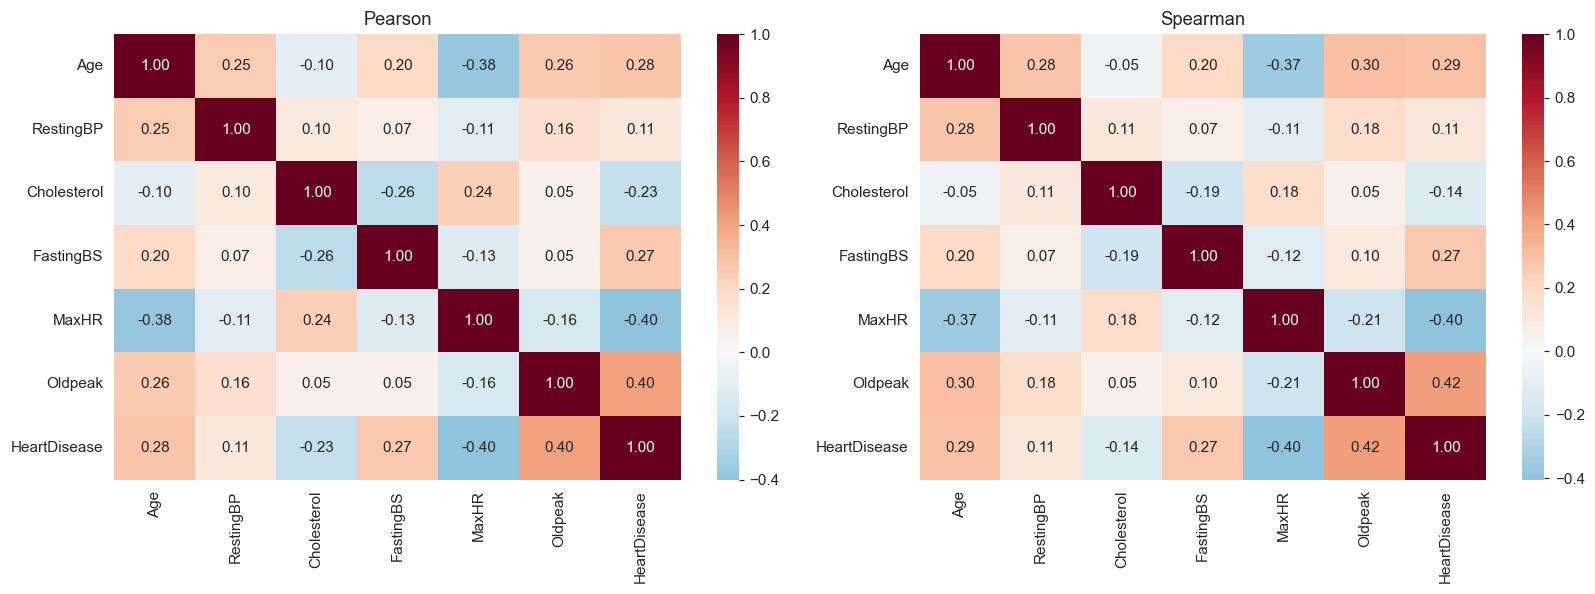

In [12]:
corr_num = df_raw.select_dtypes("number").corr(method="pearson")
corr_spr = df_raw.select_dtypes("number").corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0]); axes[0].set_title("Pearson")
sns.heatmap(corr_spr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1]); axes[1].set_title("Spearman")
plt.tight_layout(); plt.show()

**Reading:** the strongest linear links with the target are `Oldpeak` (+0.40), `MaxHR` (−0.40), `Age` (+0.28) and `FastingBS` (+0.27). `Cholesterol` has a *negative* correlation with disease (−0.23): a statistical artefact of the zeros, not clinical reality. No pair of numeric predictors is strongly correlated (the largest is `Age` vs `MaxHR`, −0.38), so there is little redundancy so far. Pearson and Spearman agree, which suggests the relationships are close to monotonic.

<a id="sec6"></a>
## 6. Data diagnostics & cleaning  *(course step 3)*

Checklist from the course: duplicates · wrong types · useless columns · missing values · aberrant values · inconsistent formats. *Garbage in, garbage out.*

### 6.1 Duplicates, types and useless columns

In [13]:
print("Duplicate rows:", df_raw.duplicated().sum())
print("Raw NaN values:", int(df_raw.isna().sum().sum()))

diag = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "top_value_share_%": df_raw.apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(1),
})
diag

Duplicate rows: 0
Raw NaN values: 0


,dtype,n_unique,top_value_share_%
Age,int64,50,5.6
Sex,object,2,79.0
ChestPainType,object,4,54.0
RestingBP,int64,67,14.4
Cholesterol,int64,222,18.7
FastingBS,int64,2,76.7
RestingECG,object,3,60.1
MaxHR,int64,119,4.7
ExerciseAngina,object,2,59.6
Oldpeak,float64,53,40.1


No duplicates, no `NaN`, no identifier column, and no constant or quasi-constant column (the most frequent value of any column is far below 100 %). Categorical columns are stored as text and will be encoded in section 8. Let us check text consistency (case, spaces):

In [14]:
for col in df_raw.select_dtypes(include=["object", "string"]).columns:
    vals = df_raw[col].unique().tolist()
    clean_vals = {v.strip().upper() for v in vals}
    print(f"{col:15s} {vals}   -> consistent: {len(vals) == len(clean_vals)}")

Sex             ['M', 'F']   -> consistent: True
ChestPainType   ['ATA', 'NAP', 'ASY', 'TA']   -> consistent: True
RestingECG      ['Normal', 'ST', 'LVH']   -> consistent: True
ExerciseAngina  ['N', 'Y']   -> consistent: True
ST_Slope        ['Up', 'Flat', 'Down']   -> consistent: True


### 6.2 Disguised missing values and impossible values

`isna()` reports no missing values, but a resting blood pressure or a serum cholesterol of **0** is physiologically impossible in a living patient: it is a *placeholder for "not recorded"*. Similarly, `Oldpeak` measures ST **depression**, so negative values deserve a look.

In [15]:
zero_tbl = pd.DataFrame({
    "n_zeros":  [(df_raw[c] == 0).sum() for c in ["RestingBP", "Cholesterol"]],
}, index=["RestingBP", "Cholesterol"])
zero_tbl["% of rows"] = (zero_tbl["n_zeros"] / len(df_raw) * 100).round(1)
display(zero_tbl)

print("Oldpeak < 0 :", (df_raw["Oldpeak"] < 0).sum(), "rows  (min =", df_raw["Oldpeak"].min(), ")")
print("Age range   :", df_raw["Age"].min(), "-", df_raw["Age"].max())
print("MaxHR range :", df_raw["MaxHR"].min(), "-", df_raw["MaxHR"].max())

,n_zeros,% of rows
RestingBP,1,0.1
Cholesterol,172,18.7


Oldpeak < 0 : 13 rows  (min = -2.6 )
Age range   : 28 - 77
MaxHR range : 60 - 202


**Why are the values missing?** Course advice: understand the *why* before choosing a strategy. Is the missingness random, or does it relate to the outcome?

In [16]:
chol_zero = df_raw["Cholesterol"].eq(0)
tab = df_raw.groupby(chol_zero)[TARGET].agg(["count", "mean"]).rename(
    index={False: "Cholesterol recorded", True: "Cholesterol = 0 (not recorded)"})
tab["mean"] = (tab["mean"] * 100).round(1)
tab.columns = ["n patients", "% with heart disease"]
display(tab)

ct = pd.crosstab(chol_zero, df_raw[TARGET])
chi2, p, _, _ = stats.chi2_contingency(ct)
print(f"Chi-square test (cholesterol missing vs target): chi2 = {chi2:.1f}, p = {p:.2e}")

,n patients,% with heart disease
Cholesterol,,
Cholesterol recorded,746,47.7
Cholesterol = 0 (not recorded),172,88.4


Chi-square test (cholesterol missing vs target): chi2 = 91.8, p = 9.50e-22


**Reading , this is the key data-quality finding.**
- 172 patients (18.7 %) have `Cholesterol = 0`, and **88 % of them have heart disease**, against 48 % among patients whose cholesterol was recorded. The difference is hugely significant (p ≈ 10⁻²¹).
- So cholesterol is **not missing at random**: it was most likely not measured for certain patient groups or hospitals in the merged sources. This explains the artefactual negative correlation seen in EDA.
- Consequences: (1) the zeros must not be treated as real values; (2) we keep the *fact* that cholesterol is missing as its own feature (`Chol_missing`); (3) we must be careful, because this feature reflects how the data was *collected*, not biology - a point we come back to in the conclusion.

### 6.3 Cleaning rules (deterministic, no learning from data)

We apply only rules that **do not depend on the data distribution**, so they can safely be applied to the full dataset *before* splitting:

1. Strip whitespace in text columns (defensive; nothing to fix here).
2. Replace impossible zeros in `Cholesterol` and `RestingBP` by `NaN`.
3. Keep the information that cholesterol was not recorded: create a binary flag **`Chol_missing`** (informative, see above).
4. Treat negative `Oldpeak` as 0 (ST *depression* cannot be negative; 13 rows). *Assumption — easy to revisit if a cardiologist advises otherwise.*

> **Imputation is NOT done here.** Replacing the `NaN` requires a statistic (median/mode) and that statistic must be computed **on the train set only**, after the split (section 7–8).
>
> ⚠️ **Methodological correction versus Week 2.** In Week 2 the zeros were imputed with the median **grouped by `HeartDisease`**. That uses the *target* to fill a *feature* , a form of target leakage: at prediction time the diagnosis is unknown, so the same rule cannot be applied to a new patient, and cross-validation scores become over-optimistic. Here we impute with the plain train-set median instead.

We wrap these rules in a function so that exactly the same cleaning is applied to new patients at deployment time (section 15).

In [17]:
FEATURES_RAW = ["Age", "Sex", "ChestPainType", "RestingBP", "Cholesterol", "FastingBS",
                "RestingECG", "MaxHR", "ExerciseAngina", "Oldpeak", "ST_Slope"]
TEXT_COLS = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]

def clean_raw(data: pd.DataFrame) -> pd.DataFrame:
    # Deterministic cleaning rules (no statistic is learned from the data).
    out = data.copy()
    for c in TEXT_COLS:
        out[c] = out[c].astype(str).str.strip()
    for c in ["Cholesterol", "RestingBP"]:
        out[c] = out[c].replace(0, np.nan)              # impossible zeros -> NaN
    out["Chol_missing"] = out["Cholesterol"].isna().astype(int)   # keep the 'not recorded' signal
    out["Oldpeak"] = out["Oldpeak"].clip(lower=0)       # ST depression cannot be negative
    return out

df_clean = clean_raw(df_raw)
print("NaN after cleaning rules:\n", df_clean.isna().sum()[lambda s: s > 0].to_string())
print("\nChol_missing flag:", df_clean["Chol_missing"].sum(), "patients")
df_clean.head()

NaN after cleaning rules:
 RestingBP        1
Cholesterol    172

Chol_missing flag: 172 patients


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Chol_missing
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,0
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,0
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,0


<a id="sec7"></a>
## 7. Train / test split  *(course step 4)*

The split happens **before** imputation, scaling and encoding so that no information from the test set leaks into the training process (*data leakage*).

- **Size:** the course gives 70/30 or 90/10 as examples and says the test size depends on the dataset size. With 918 rows, we use **80 % / 20 %**: enough training data to learn from while keeping ~184 test patients for a meaningful evaluation.
- **Stratified** on the target: both sets keep the same proportion of sick patients.
- Fixed `random_state` for reproducibility.

In [18]:
FEATURES = FEATURES_RAW + ["Chol_missing"]
X = df_clean[FEATURES]
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "% of data": [len(X_train) / len(X) * 100, len(X_test) / len(X) * 100],
    "% heart disease": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Test"]).round(1)
display(summary)

# From now on the test set is NOT touched until section 13.

,rows,% of data,% heart disease
Train,734,80.0,55.3
Test,184,20.0,55.4


<a id="sec8"></a>
## 8. Feature engineering & preprocessing  *(course step 5)*

Transformations depend on the type of variable and on the models we plan to use (distance-based and linear models are sensitive to scale; trees are not).

| Variable type | Columns | Treatment (learned on **train only**) |
|---|---|---|
| Numeric, roughly symmetric | `Age`, `RestingBP`, `Cholesterol`, `MaxHR` | Median imputation → **standardisation** (mean 0, std 1) |
| Numeric, right-skewed | `Oldpeak` | **log(1 + x)** → standardisation |
| Binary categorical | `Sex`, `ExerciseAngina` | **Label (0/1) encoding** |
| Ordinal categorical | `ST_Slope` (Down < Flat < Up) | **Ordinal encoding** |
| Nominal categorical | `ChestPainType`, `RestingECG` | **One-hot encoding** |
| Already binary | `FastingBS`, `Chol_missing` | Kept as is |

Categorical columns also get a most-frequent imputer: there are no missing categories in this dataset, but a deployed model must not crash on an incomplete record.

### 8.1 Is the log transform justified? (train set only)

Skewness on the train set:
 Age           -0.21
RestingBP      0.63
Cholesterol    1.24
MaxHR         -0.19
Oldpeak        1.12

Oldpeak skewness after log1p: 0.42


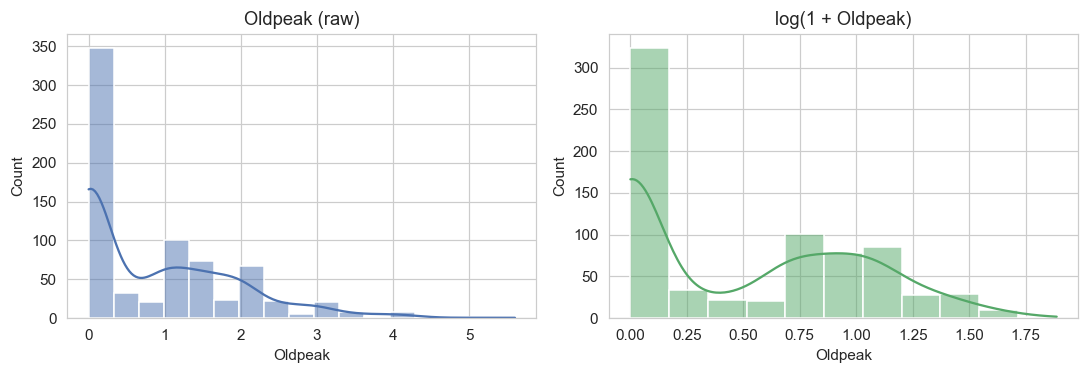

In [19]:
skew_train = X_train[["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]].skew().round(2)
print("Skewness on the train set:\n", skew_train.to_string())
print("\nOldpeak skewness after log1p:", round(np.log1p(X_train["Oldpeak"]).skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(X_train["Oldpeak"], kde=True, ax=axes[0], color="#4C72B0"); axes[0].set_title("Oldpeak (raw)")
sns.histplot(np.log1p(X_train["Oldpeak"]), kde=True, ax=axes[1], color="#55A868"); axes[1].set_title("log(1 + Oldpeak)")
plt.tight_layout(); plt.show()

**Reading:** on the train set `Oldpeak` has a skewness of 1.12, reduced to 0.42 by `log(1 + x)` — a clear improvement, so the log transform is kept for this variable. `Cholesterol` also has a high skewness (1.24) but only because of the zeros that will be imputed; after imputation it is much more symmetric, so it is not log-transformed.

### 8.2 The preprocessing pipeline

In [20]:
NUM_STD   = ["Age", "RestingBP", "Cholesterol", "MaxHR"]
NUM_SKEW  = ["Oldpeak"]
BIN_COLS  = ["Sex", "ExerciseAngina"]
ORD_COLS  = ["ST_Slope"]
OHE_COLS  = ["ChestPainType", "RestingECG"]
PASS_COLS = ["FastingBS", "Chol_missing"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num",  Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale",  StandardScaler())]), NUM_STD),
        ("skew", Pipeline([("log",   FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("scale", StandardScaler())]), NUM_SKEW),
        ("bin",  Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("enc",    OrdinalEncoder(categories=[["F", "M"], ["N", "Y"]]))]), BIN_COLS),
        ("ord",  Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("enc",    OrdinalEncoder(categories=[["Down", "Flat", "Up"]]))]), ORD_COLS),
        ("ohe",  Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("enc",    OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), OHE_COLS),
        ("pass", "passthrough", PASS_COLS),
    ],
    verbose_feature_names_out=False,
)

# Exploration copy: fit on TRAIN only, then apply to train and test
prep_explore = clone(preprocessor).set_output(transform="pandas")
X_train_prep = prep_explore.fit_transform(X_train)
X_test_prep  = prep_explore.transform(X_test)

print("Train matrix:", X_train_prep.shape, "| Test matrix:", X_test_prep.shape)
print("Median used to impute Cholesterol (train only):",
      prep_explore.named_transformers_["num"].named_steps["impute"].statistics_[2].round(1))
X_train_prep.head()

Train matrix: (734, 17) | Test matrix: (184, 17)
Median used to impute Cholesterol (train only): 238.0


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex,ExerciseAngina,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,FastingBS,Chol_missing
485,0.970012,0.339016,-0.517499,-0.324520,0.571582,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1,0
486,0.122028,-1.266031,-0.572835,1.689837,-0.317524,1.0,0.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1,0
117,0.546020,-0.159102,1.714383,-0.247045,0.823045,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1,0
361,-0.725956,1.501291,-0.130147,-0.479470,-0.979402,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0,1
296,-0.407962,0.671094,-0.130147,0.101594,0.064403,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1,1


### 8.3 Quality check after transformation (EDA #2)

In [21]:
chk = X_train_prep.agg(["mean", "std", "min", "max"]).T.round(2)
display(chk)
print("Remaining NaN in train / test:", X_train_prep.isna().sum().sum(), "/", X_test_prep.isna().sum().sum())

,mean,std,min,max
Age,0.00,1.00,-2.63,2.45
RestingBP,-0.00,1.00,-2.26,3.72
Cholesterol,0.00,1.00,-2.95,6.60
MaxHR,-0.00,1.00,-2.96,2.54
Oldpeak,0.00,1.00,-0.98,2.73
Sex,0.79,0.41,0.00,1.00
ExerciseAngina,0.41,0.49,0.00,1.00
ST_Slope,1.36,0.60,0.00,2.00
ChestPainType_ASY,0.55,0.50,0.00,1.00
ChestPainType_ATA,0.19,0.39,0.00,1.00


Remaining NaN in train / test: 0 / 0


**Reading:** the numeric columns are centred (mean 0) and scaled (std 1) using train statistics, the categorical columns became 0/1 indicators, and no `NaN` remains in train or test. The test set is transformed with the *train* parameters (e.g. cholesterol imputed with the train median, 238 mg/dl), so its mean/std are not exactly 0/1 — which is expected and correct. We end up with 17 model-ready columns.

<a id="sec9"></a>
## 9. Feature selection  *(course step 5, part G)*

Too many (redundant) variables increase computation time and can hurt prediction. Selection criteria from the course, **all computed on the train set only**:

1. Variables too correlated with each other (|r| > 0.95) → drop one of the pair.
2. Variables with very low variance (quasi-constant) → drop.
3. Categorical variables → **chi-square test** of dependence with the target.
4. Numerical variables → correlation with the target.
5. Variables with too many missing values → drop.

### 9.1 Redundancy: pairwise correlations

|correlation|
RestingECG_LVH    RestingECG_Normal           0.62
RestingECG_Normal RestingECG_ST               0.61
ChestPainType_ASY ChestPainType_NAP           0.57
Oldpeak           ST_Slope                    0.55
ChestPainType_ASY ChestPainType_ATA           0.53
Oldpeak           ExerciseAngina              0.46
ExerciseAngina    ST_Slope                    0.45
                  ChestPainType_ASY           0.42

Features with |r| > 0.95 with another feature: none


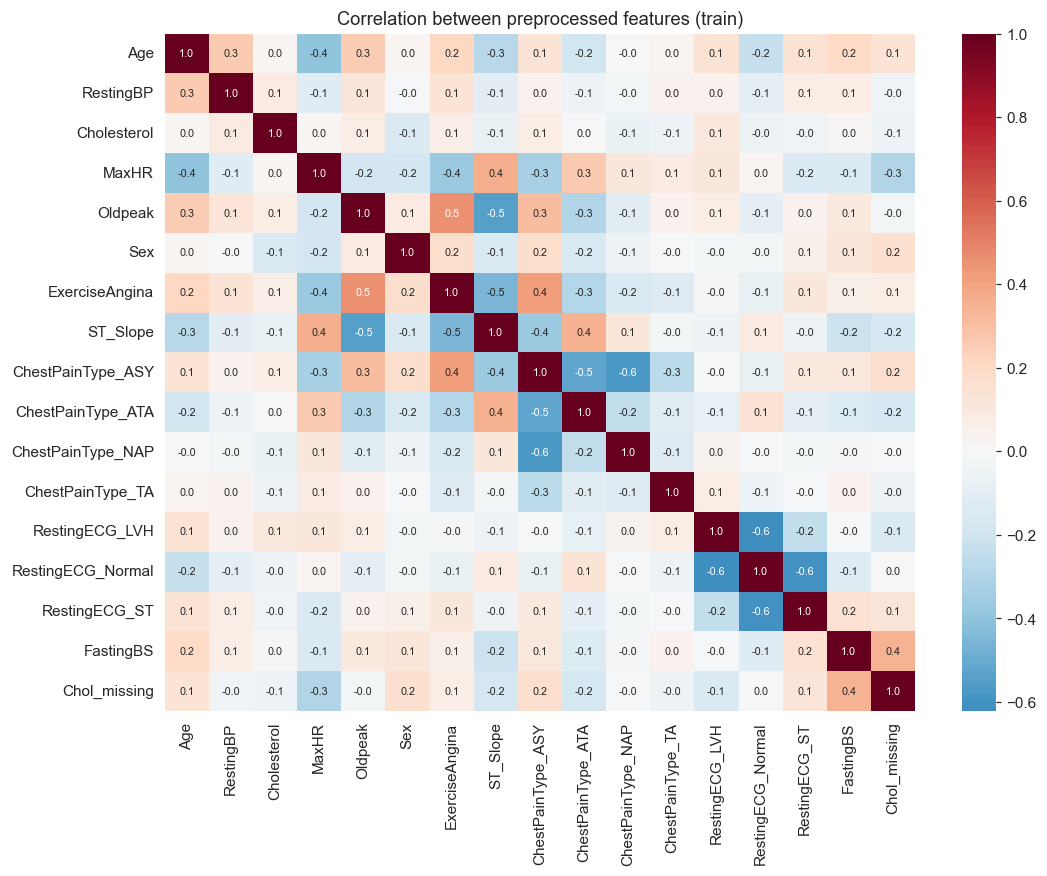

In [22]:
corr_tr = X_train_prep.corr().abs()
upper = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool))
pairs = (upper.stack().sort_values(ascending=False).head(8)
         .rename("|correlation|").to_frame())
display(pairs.round(2))

high = [c for c in upper.columns if (upper[c] > 0.95).any()]
print("Features with |r| > 0.95 with another feature:", high if high else "none")

plt.figure(figsize=(11, 8))
sns.heatmap(X_train_prep.corr(), cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation between preprocessed features (train)"); plt.show()

### 9.2 Variance and missingness

In [23]:
dominant = X_train_prep.apply(lambda s: s.round(6).value_counts(normalize=True).iloc[0]).sort_values(ascending=False)
print("Highest share held by a single value (quasi-constant if > 0.98):")
print(dominant.head(5).round(3).to_string())
print("\nMissing share in raw train features (max):", f"{X_train.isna().mean().max()*100:.1f}%  ({X_train.isna().mean().idxmax()})")

Highest share held by a single value (quasi-constant if > 0.98):
ChestPainType_TA     0.946
Chol_missing         0.824
ChestPainType_ATA    0.815
RestingECG_ST        0.808
RestingECG_LVH       0.801

Missing share in raw train features (max): 17.6%  (Cholesterol)


### 9.3 Relationship with the target

,chi2,p_value,cramers_v,significant (p<0.05)
feature,,,,
ST_Slope,309.1753,0.0000,0.6490,True
ChestPainType,214.3394,0.0000,0.5404,True
ExerciseAngina,174.8591,0.0000,0.4881,True
Chol_missing,74.1518,0.0000,0.3178,True
Sex,56.2632,0.0000,0.2769,True
FastingBS,48.9072,0.0000,0.2581,True
RestingECG,9.7690,0.0076,0.1154,True


,pearson_with_target,spearman_with_target,mutual_info
Age,0.245,0.255,0.056
RestingBP,0.102,0.107,0.021
Cholesterol,0.055,0.087,0.057
MaxHR,-0.407,-0.411,0.100
Oldpeak,0.416,0.404,0.089


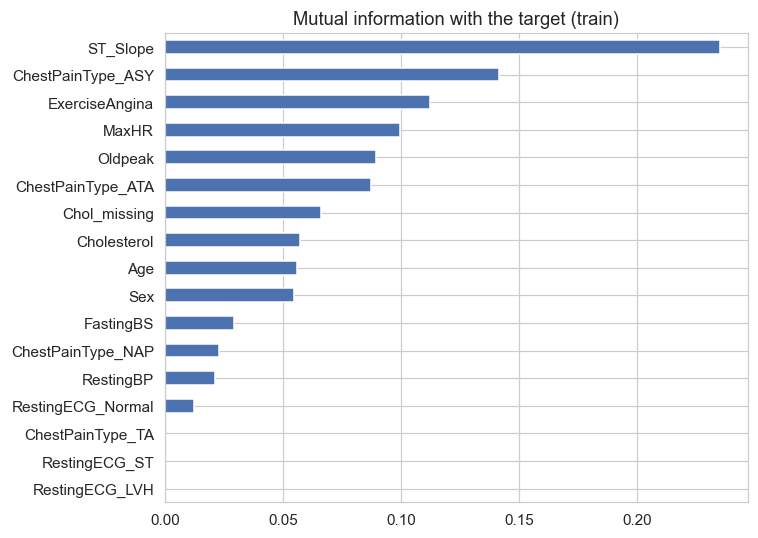

In [24]:
# Categorical variables: chi-square test + Cramer's V (effect size)
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

rows = []
for col in TEXT_COLS + ["FastingBS", "Chol_missing"]:
    ct = pd.crosstab(X_train[col], y_train)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append((col, chi2, p, cramers_v(ct)))
chi_tbl = (pd.DataFrame(rows, columns=["feature", "chi2", "p_value", "cramers_v"])
           .set_index("feature").sort_values("chi2", ascending=False))
chi_tbl["significant (p<0.05)"] = chi_tbl["p_value"] < 0.05
display(chi_tbl.round(4))

# Numerical variables: correlation with target + mutual information (on preprocessed train data)
num_names = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
num_tbl = pd.DataFrame({
    "pearson_with_target": [np.corrcoef(X_train_prep[c], y_train)[0, 1] for c in num_names],
    "spearman_with_target": [stats.spearmanr(X_train_prep[c], y_train)[0] for c in num_names],
}, index=num_names)
mi = mutual_info_classif(X_train_prep, y_train, random_state=RANDOM_STATE)
num_tbl["mutual_info"] = pd.Series(mi, index=X_train_prep.columns)[num_names]
display(num_tbl.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
pd.Series(mi, index=X_train_prep.columns).sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Mutual information with the target (train)"); plt.tight_layout(); plt.show()

**Decision:**
- **Redundancy:** no pair of features has |r| > 0.95 (the highest is 0.62, between two one-hot columns of the same variable, which is mechanical). Nothing to drop.
- **Variance:** no quasi-constant feature (the most unbalanced one, `ChestPainType_TA`, still has ~5 % positives). Nothing to drop.
- **Missingness:** the maximum is 17.6 % (`Cholesterol`), already handled by imputation + flag; no column exceeds a drop threshold.
- **Link with the target:** every categorical variable is significantly associated with the target (χ² p < 0.05). The strongest are `ST_Slope` (Cramér's V = 0.65), `ChestPainType` (0.54) and `ExerciseAngina` (0.49); `RestingECG` is the weakest (0.12). Numerically, `Oldpeak` and `MaxHR` carry the most information; `Cholesterol`, `RestingBP` and `Age` are weaker individually but are kept because they may interact with other variables and are standard clinical risk factors.

➡️ **All 17 features are kept.** With only 11 original variables, aggressive selection would risk discarding useful signal for no computational gain. (Week 2's `HR_Reserve` is not recreated: it was ~93 % correlated with `MaxHR` by construction.)

<a id="sec10"></a>
## 10. Model choice  *(course step 6)*

- The dataset has a labelled target → **supervised learning**.
- The target is categorical (binary) → **classification**.
- There is no universal best model: we **start with a simple, explainable baseline** and add complexity only if it helps. We compare several families on identical data and identical metrics.

| Model | Role | Why it is in the comparison |
|---|---|---|
| `DummyClassifier` | Floor | Any useful model must beat "always predict the majority class" |
| Logistic regression | **Simple baseline** | Fast, explainable (odds ratios), strong on tabular clinical data |
| K-nearest neighbours | Distance-based | Benefits from our scaling |
| Decision tree | Interpretable non-linear | Easy to read, but prone to overfitting |
| Random forest | Bagging ensemble | Robust, little tuning |
| Gradient boosting | Boosting ensemble | Often best on tabular data |
| SVM (RBF) | Kernel method | Strong on small, scaled datasets |
| XGBoost *(if installed)* | Boosting | Popular reference implementation |

Each model is wrapped in a **Pipeline = preprocessing + model**. This guarantees that imputation, scaling and encoding are re-learned **inside every cross-validation fold** on the training part only — no leakage.

In [26]:
def make_pipe(model):
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])

models = {
    "Dummy (majority)":     DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":  LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN":                  KNeighborsClassifier(n_neighbors=15),
    "Decision Tree":        DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)":            SVC(probability=True, random_state=RANDOM_STATE),
}
if HAS_XGB:
    models["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                      eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

pipes = {name: make_pipe(m) for name, m in models.items()}
print("Candidate models:", list(pipes))

Candidate models: ['Dummy (majority)', 'Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM (RBF)']


<a id="sec11"></a>
## 11. Baseline training & cross-validation  *(course step 7 — part 6.1)*

**Cross-validation** splits the *training set* into folds; the model is trained on all folds but one and evaluated on the remaining one, in turn. It gives a more reliable estimate than a single split and lets us **choose among models without touching the test set**.

We use **5-fold stratified CV repeated 3 times** (15 evaluations per model) and report the mean ± standard deviation. Comparing training and validation scores also reveals **overfitting**.

In [27]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

cv_results, cv_raw = [], {}
for name, pipe in pipes.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    cv_raw[name] = res
    row = {"model": name}
    for m in scoring:
        row[f"{m}"] = f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}"
    row["_auc_mean"] = res["test_roc_auc"].mean()
    row["train_auc"] = res["train_roc_auc"].mean()
    row["auc_gap (train-val)"] = res["train_roc_auc"].mean() - res["test_roc_auc"].mean()
    cv_results.append(row)

cv_table = (pd.DataFrame(cv_results).set_index("model")
            .sort_values("_auc_mean", ascending=False).drop(columns="_auc_mean"))
cv_table["train_auc"] = cv_table["train_auc"].round(3)
cv_table["auc_gap (train-val)"] = cv_table["auc_gap (train-val)"].round(3)
cv_table

,accuracy,precision,recall,f1,roc_auc,train_auc,auc_gap (train-val)
model,,,,,,,
Random Forest,0.851 ± 0.026,0.844 ± 0.038,0.899 ± 0.024,0.870 ± 0.020,0.927 ± 0.025,1.000,0.073
Gradient Boosting,0.857 ± 0.026,0.866 ± 0.034,0.880 ± 0.031,0.872 ± 0.022,0.924 ± 0.022,0.994,0.070
Logistic Regression,0.851 ± 0.027,0.857 ± 0.038,0.879 ± 0.020,0.867 ± 0.021,0.920 ± 0.029,0.931,0.011
SVM (RBF),0.856 ± 0.028,0.851 ± 0.041,0.901 ± 0.017,0.875 ± 0.021,0.918 ± 0.026,0.960,0.043
KNN,0.822 ± 0.035,0.831 ± 0.046,0.855 ± 0.037,0.842 ± 0.029,0.902 ± 0.029,0.928,0.026
Decision Tree,0.794 ± 0.050,0.820 ± 0.054,0.806 ± 0.054,0.812 ± 0.046,0.792 ± 0.051,1.000,0.208
Dummy (majority),0.553 ± 0.003,0.553 ± 0.003,1.000 ± 0.000,0.712 ± 0.002,0.500 ± 0.000,0.500,0.000


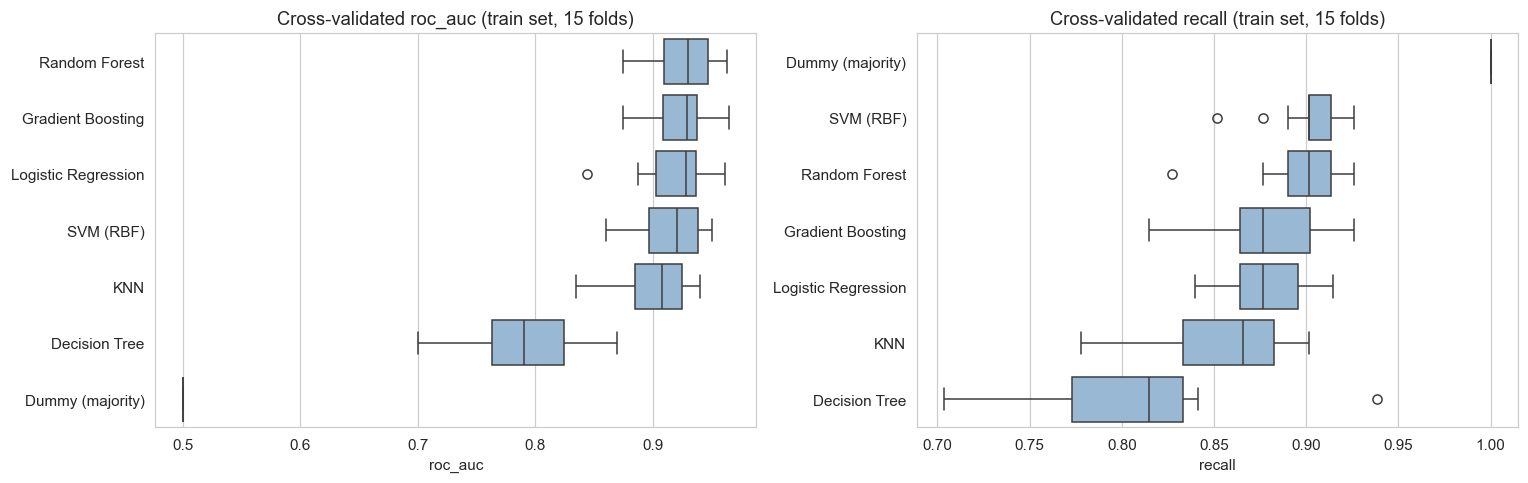

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["roc_auc", "recall"]):
    data = pd.DataFrame({n: r[f"test_{metric}"] for n, r in cv_raw.items()})
    order = data.mean().sort_values(ascending=False).index
    sns.boxplot(data=data[order], orient="h", ax=ax, color="#8FB8DE")
    ax.set_title(f"Cross-validated {metric} (train set, 15 folds)"); ax.set_xlabel(metric)
plt.tight_layout(); plt.show()

**Reading:**
- Every model beats the **dummy baseline** (AUC 0.50; its recall of 1.0 is trivial — it predicts "disease" for everyone — and its precision is only the 55 % prevalence).
- The simple **logistic regression** is already strong (AUC ≈ 0.92) and, importantly, shows almost no overfitting (train–validation gap 0.011). The ensembles (Random Forest, XGBoost, Gradient Boosting) are slightly better (AUC ≈ 0.925) but their training AUC is ≈ 1.0, a gap of ~0.07: they memorise the training data more.
- The single **decision tree** overfits heavily (gap 0.21, AUC 0.79) and is clearly the worst non-trivial model.
- Differences between the top models (≈ 0.92–0.93) are **smaller than the fold-to-fold standard deviation** (≈ 0.025): they are not statistically distinguishable. This is typical of small tabular datasets model choice here matters less than data quality and honest validation.

<a id="sec12"></a>
## 12. Hyperparameter tuning  *(course step 7 - part 6.2)*

If the baseline is not good enough, we search better hyperparameters:

- **GridSearchCV**, exhaustive search on a small grid (used for logistic regression, SVM, KNN).
- **RandomizedSearchCV**, random sampling of a large space (used for the tree ensembles).
- *(Bayesian optimisation is a third option, not used here.)*

Search criterion: **ROC-AUC** by 5-fold stratified CV on the **train set**. The test set is still untouched.

In [29]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

searches = {
    "Logistic Regression": GridSearchCV(
        pipes["Logistic Regression"],
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
         "model__penalty": ["l1", "l2"], "model__solver": ["liblinear"]},
        scoring="roc_auc", cv=inner_cv, n_jobs=-1),
    "SVM (RBF)": GridSearchCV(
        pipes["SVM (RBF)"],
        {"model__C": [0.1, 0.3, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.03, 0.1]},
        scoring="roc_auc", cv=inner_cv, n_jobs=-1),
    "KNN": GridSearchCV(
        pipes["KNN"],
        {"model__n_neighbors": [5, 9, 15, 21, 31], "model__weights": ["uniform", "distance"]},
        scoring="roc_auc", cv=inner_cv, n_jobs=-1),
    "Random Forest": RandomizedSearchCV(
        pipes["Random Forest"],
        {"model__n_estimators": [200, 400, 600],
         "model__max_depth": [3, 4, 5, 6, 8, None],
         "model__min_samples_leaf": [1, 2, 4, 8],
         "model__max_features": ["sqrt", 0.5, 0.8]},
        n_iter=30, scoring="roc_auc", cv=inner_cv, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": RandomizedSearchCV(
        pipes["Gradient Boosting"],
        {"model__n_estimators": [50, 100, 200, 300],
         "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
         "model__max_depth": [2, 3, 4],
         "model__subsample": [0.6, 0.8, 1.0],
         "model__min_samples_leaf": [1, 3, 5, 10]},
        n_iter=30, scoring="roc_auc", cv=inner_cv, n_jobs=-1, random_state=RANDOM_STATE),
}
if HAS_XGB:
    searches["XGBoost"] = RandomizedSearchCV(
        pipes["XGBoost"],
        {"model__n_estimators": [100, 200, 300, 500],
         "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
         "model__max_depth": [2, 3, 4, 5],
         "model__subsample": [0.6, 0.8, 1.0],
         "model__colsample_bytree": [0.6, 0.8, 1.0],
         "model__min_child_weight": [1, 3, 5]},
        n_iter=30, scoring="roc_auc", cv=inner_cv, n_jobs=-1, random_state=RANDOM_STATE)

tuned, tune_rows = {}, []
for name, s in searches.items():
    s.fit(X_train, y_train)
    tuned[name] = s.best_estimator_
    base_auc = cv_raw[name]["test_roc_auc"].mean()
    tune_rows.append({"model": name, "baseline CV AUC": base_auc, "tuned CV AUC": s.best_score_,
                      "best params": {k.replace("model__", ""): v for k, v in s.best_params_.items()}})

tune_table = pd.DataFrame(tune_rows).set_index("model").sort_values("tuned CV AUC", ascending=False)
tune_table[["baseline CV AUC", "tuned CV AUC"]] = tune_table[["baseline CV AUC", "tuned CV AUC"]].round(4)
pd.set_option("display.max_colwidth", 120)
tune_table

,baseline CV AUC,tuned CV AUC,best params
model,,,
Gradient Boosting,0.9236,0.9344,"{'subsample': 0.8, 'n_estimators': 50, 'min_samples_leaf': 10, 'max_depth': 4, 'learning_rate': 0.1}"
Random Forest,0.9266,0.9325,"{'n_estimators': 200, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': None}"
SVM (RBF),0.9175,0.9218,"{'C': 1, 'gamma': 0.1}"
Logistic Regression,0.9198,0.9209,"{'C': 0.3, 'penalty': 'l1', 'solver': 'liblinear'}"
KNN,0.9024,0.9043,"{'n_neighbors': 21, 'weights': 'distance'}"


**Reading:** tuning gives small but consistent gains for the ensembles (e.g. gradient boosting 0.924 → 0.934) and almost none for logistic regression and KNN. The best tuned models are again within noise of each other, and these gains are measured on the same folds used for the search, so they are slightly optimistic, one more reason to rely on the untouched test set for the final judgement.

### 12.1 Selecting the final model - using the train set only

The final model is the one with the best **cross-validated** AUC on the train set. If several models are within noise of each other, the course advice applies: *prefer the simpler, more explainable one* , it is also cheaper to run and easier to defend to clinicians.

In [30]:
best_name = tune_table["tuned CV AUC"].idxmax()
best_auc = tune_table.loc[best_name, "tuned CV AUC"]

# Models within 0.005 AUC of the best (practically equivalent given CV noise)
close = tune_table.index[tune_table["tuned CV AUC"] >= best_auc - 0.005].tolist()
print("Best by CV AUC:", best_name, f"({best_auc:.4f})")
print("Within 0.005 AUC (practically equivalent):", close)

# Simplicity ranking (simplest first)
simplicity = ["Logistic Regression", "KNN", "SVM (RBF)", "Random Forest", "Gradient Boosting", "XGBoost"]
final_name = next(m for m in simplicity if m in close)
final_model = tuned[final_name]
print("\n>>> FINAL MODEL SELECTED:", final_name)

Best by CV AUC: Gradient Boosting (0.9344)
Within 0.005 AUC (practically equivalent): ['Gradient Boosting', 'Random Forest']

>>> FINAL MODEL SELECTED: Random Forest


<a id="sec13"></a>
## 13. Final evaluation on the test set  *(course step 8)*

For the first time we use the **test set**, independent data the model has never seen (not for fitting, not for imputation, not for tuning). All tuned models are scored on the same test data and the same metrics; the *selection* above was made without looking at these numbers.

In [31]:
def evaluate(model, X_, y_, threshold=0.5):
    proba = model.predict_proba(X_)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_, pred), "precision": precision_score(y_, pred),
            "recall": recall_score(y_, pred), "f1": f1_score(y_, pred), "roc_auc": roc_auc_score(y_, proba)}

# Baseline floor + all tuned models
dummy = pipes["Dummy (majority)"].fit(X_train, y_train)
test_rows = {"Dummy (majority)": evaluate(dummy, X_test, y_test)}
for name, mdl in tuned.items():
    test_rows[name] = evaluate(mdl, X_test, y_test)

test_table = pd.DataFrame(test_rows).T.sort_values("roc_auc", ascending=False).round(3)
test_table["selected"] = ["◄ final" if n == final_name else "" for n in test_table.index]
test_table

,accuracy,precision,recall,f1,roc_auc,selected
Random Forest,0.902,0.904,0.922,0.913,0.933,◄ final
KNN,0.880,0.908,0.873,0.890,0.933,
SVM (RBF),0.870,0.875,0.892,0.883,0.923,
Gradient Boosting,0.870,0.898,0.863,0.880,0.922,
Logistic Regression,0.870,0.868,0.902,0.885,0.912,
Dummy (majority),0.554,0.554,1.000,0.713,0.500,


In [32]:
# Overfitting check for the final model: train vs CV vs test
train_m = evaluate(final_model, X_train, y_train)
test_m  = evaluate(final_model, X_test, y_test)
cv_auc  = tune_table.loc[final_name, "tuned CV AUC"]
print(f"{final_name}")
print(f"  AUC  train = {train_m['roc_auc']:.3f} | CV (train) = {cv_auc:.3f} | test = {test_m['roc_auc']:.3f}")
print(f"  Acc  train = {train_m['accuracy']:.3f} | test = {test_m['accuracy']:.3f}")

Random Forest
  AUC  train = 0.983 | CV (train) = 0.932 | test = 0.933
  Acc  train = 0.932 | test = 0.902


### 13.1 Confusion matrix, classification report and curves

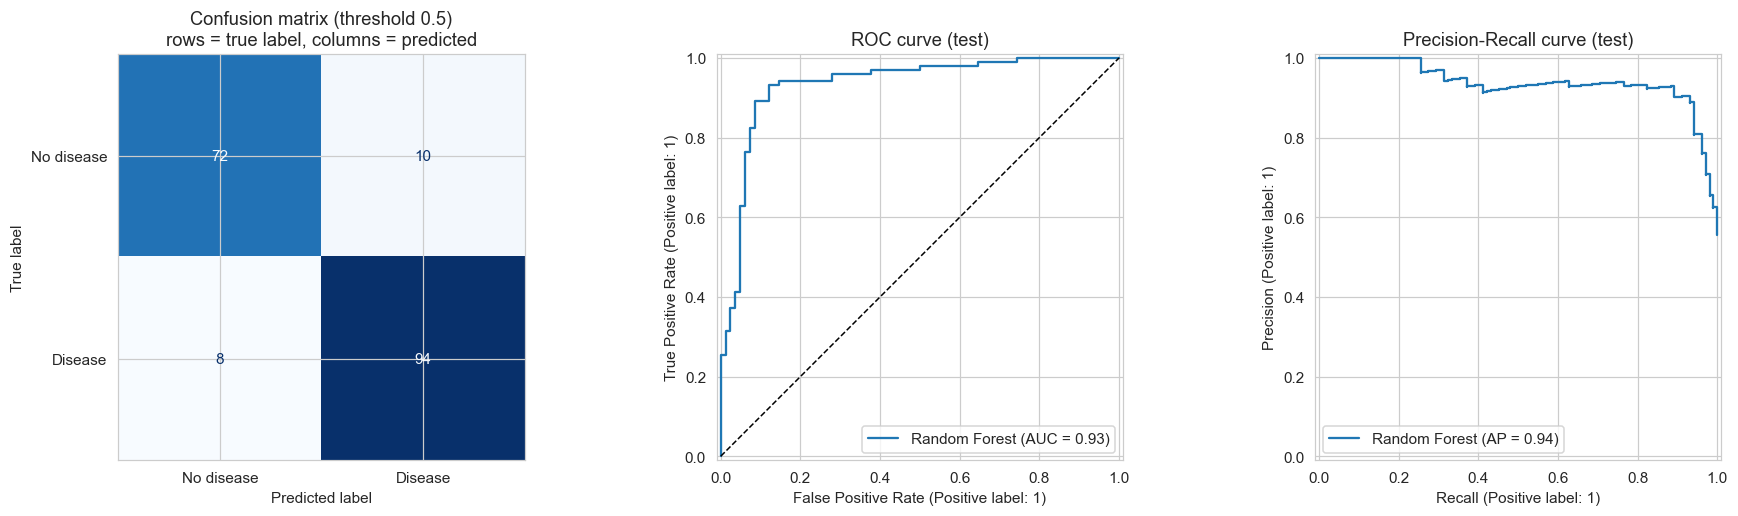

True negatives = 72 | False positives = 10 | False negatives = 8 | True positives = 94
Specificity (true-negative rate) = 0.878 | Sensitivity/recall = 0.922

              precision    recall  f1-score   support

  No disease      0.900     0.878     0.889        82
     Disease      0.904     0.922     0.913       102

    accuracy                          0.902       184
   macro avg      0.902     0.900     0.901       184
weighted avg      0.902     0.902     0.902       184



In [33]:
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test  = (proba_test >= 0.5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["No disease", "Disease"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (threshold 0.5)\nrows = true label, columns = predicted")
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1], name=final_name)
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("ROC curve (test)")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2], name=final_name)
axes[2].set_title("Precision-Recall curve (test)")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"True negatives = {tn} | False positives = {fp} | False negatives = {fn} | True positives = {tp}")
print(f"Specificity (true-negative rate) = {tn/(tn+fp):.3f} | Sensitivity/recall = {tp/(tp+fn):.3f}\n")
print(classification_report(y_test, pred_test, target_names=["No disease", "Disease"], digits=3))

**Reading (final model: Random Forest, threshold 0.5):**
- **Accuracy 0.90, precision 0.90, recall 0.92, F1 0.91, AUC 0.93.** The test AUC (0.933) matches the cross-validated AUC (0.932): the validation procedure was honest and the estimate is not inflated by leakage.
- Out of 102 sick patients, **94 are detected and 8 are missed**; out of 82 healthy patients, 72 are correctly cleared and 10 receive a false alarm.
- Several models are essentially tied on the test set (Random Forest and XGBoost reach the same accuracy; KNN has the same AUC). With only 184 test patients, differences of one or two percentage points are noise — see the confidence intervals below.
- The model is somewhat overfit (train AUC 0.98 vs test 0.93), which is normal for a random forest and not alarming since the test performance is as predicted by cross-validation.
- The result sits at the upper end of the range usually reported for this dataset (see section 1).

<a id="sec14"></a>
## 14. Additional validation

A single number on 184 patients is noisy, and a model is more than its accuracy. We check five more things:

1. **Uncertainty** of the test metrics (bootstrap confidence intervals)
2. **Bias vs. variance** (learning curve)
3. **Decision threshold** (recall vs. precision trade-off, chosen without using the test set)
4. **Interpretability** (permutation importance; coefficients if the model is linear)
5. **Subgroup performance** (men vs. women)

### 14.1 Bootstrap confidence intervals (test set)

In [34]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = {"accuracy": [], "recall": [], "precision": [], "f1": [], "roc_auc": []}
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if len(np.unique(y_arr[idx])) < 2: continue
    p, yb = proba_test[idx], y_arr[idx]; pr = (p >= 0.5).astype(int)
    boot["accuracy"].append(accuracy_score(yb, pr)); boot["recall"].append(recall_score(yb, pr))
    boot["precision"].append(precision_score(yb, pr, zero_division=0)); boot["f1"].append(f1_score(yb, pr))
    boot["roc_auc"].append(roc_auc_score(yb, p))

ci = pd.DataFrame({m: {"estimate": test_m[m], "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5)}
                   for m, v in boot.items()}).T.round(3)
ci

,estimate,95% CI low,95% CI high
accuracy,0.902,0.859,0.940
recall,0.922,0.865,0.970
precision,0.904,0.845,0.957
f1,0.913,0.868,0.950
roc_auc,0.933,0.892,0.967


### 14.2 Learning curve (bias vs. variance)

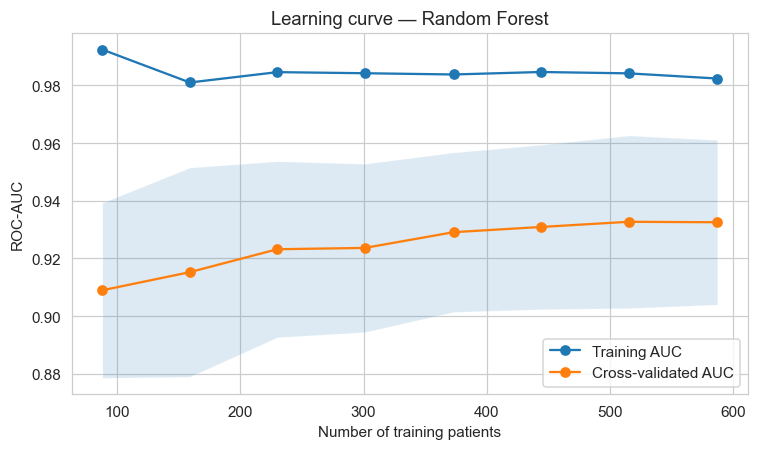

In [35]:
sizes, tr_sc, va_sc = learning_curve(clone(final_model), X_train, y_train, cv=inner_cv, scoring="roc_auc",
                                     train_sizes=np.linspace(0.15, 1.0, 8), n_jobs=-1, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(sizes, tr_sc.mean(1), "o-", label="Training AUC")
ax.plot(sizes, va_sc.mean(1), "o-", label="Cross-validated AUC")
ax.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.15)
ax.set_xlabel("Number of training patients"); ax.set_ylabel("ROC-AUC"); ax.set_title(f"Learning curve — {final_name}")
ax.legend(); plt.tight_layout(); plt.show()

**Reading:** training AUC stays near 0.98 while the cross-validated AUC climbs from 0.91 to 0.93 and has not fully plateaued. The persistent gap indicates a **variance** problem (the model fits the training set better than new patients) rather than high bias; more patients would help slightly. Collecting more data , especially for women and for patients with recorded cholesterol , is a better lever than a more complex algorithm.

### 14.3 Decision threshold

By default a patient is flagged as sick when the predicted probability ≥ 0.5. Because a **missed diagnosis costs more than a false alarm**, we examine a lower threshold. To avoid tuning on the test set, the threshold is chosen from **out-of-fold predictions on the train set** (rule: the highest threshold that still reaches 90 % recall), then applied once to the test set.

In [36]:
oof = cross_val_predict(clone(final_model), X_train, y_train, cv=inner_cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = np.where(rec[:-1] >= 0.90)[0]
THRESHOLD = float(thr[ok].max()) if len(ok) else 0.5
print(f"Chosen threshold (train out-of-fold, recall >= 0.90): {THRESHOLD:.3f}\n")

# Trade-off table on the TRAIN out-of-fold predictions (the test set is not used to explore thresholds)
sweep = pd.DataFrame([{"threshold": t,
                       "recall": recall_score(y_train, oof >= t),
                       "precision": precision_score(y_train, oof >= t),
                       "false alarms (FP)": int(((oof >= t) & (y_train == 0)).sum()),
                       "missed patients (FN)": int(((oof < t) & (y_train == 1)).sum())}
                      for t in [0.2, 0.3, 0.4, 0.5, 0.6]]).set_index("threshold").round(3)
display(sweep)

rows = {"threshold 0.50": evaluate(final_model, X_test, y_test, 0.5),
        f"threshold {THRESHOLD:.2f}": evaluate(final_model, X_test, y_test, THRESHOLD)}
display(pd.DataFrame(rows).T.round(3))

pred_thr = (proba_test >= THRESHOLD).astype(int)
tn2, fp2, fn2, tp2 = confusion_matrix(y_test, pred_thr).ravel()
print(f"With threshold {THRESHOLD:.2f}: missed patients (FN) = {fn2} (vs {fn} at 0.50), false alarms (FP) = {fp2} (vs {fp} at 0.50)")

Chosen threshold (train out-of-fold, recall >= 0.90): 0.494



,recall,precision,false alarms (FP),missed patients (FN)
threshold,,,,
0.2,0.988,0.726,151,5
0.3,0.973,0.782,110,11
0.4,0.943,0.822,83,23
0.5,0.892,0.856,61,44
0.6,0.830,0.892,41,69


,accuracy,precision,recall,f1,roc_auc
threshold 0.50,0.902,0.904,0.922,0.913,0.933
threshold 0.49,0.908,0.905,0.931,0.918,0.933


With threshold 0.49: missed patients (FN) = 7 (vs 8 at 0.50), false alarms (FP) = 10 (vs 10 at 0.50)


**Reading:** the recall/precision trade-off is explicit. On out-of-fold training predictions, the default 0.5 threshold gives ~89 % recall; reaching 94 % recall (threshold 0.4) costs some precision (86 % → 82 %), and ~97 % recall (threshold 0.3) brings precision down to ~78 %. The rule "highest threshold with recall ≥ 90 %" selects ≈ 0.49, practically the default. so on this data the standard threshold is already well placed, and moving it changes very little on the test set. If clinicians judge that missing 1 sick patient in 10 is too many, a threshold around 0.3–0.4 is the lever to discuss with them: it detects more patients at the price of more false alarms.

### 14.4 Interpretability

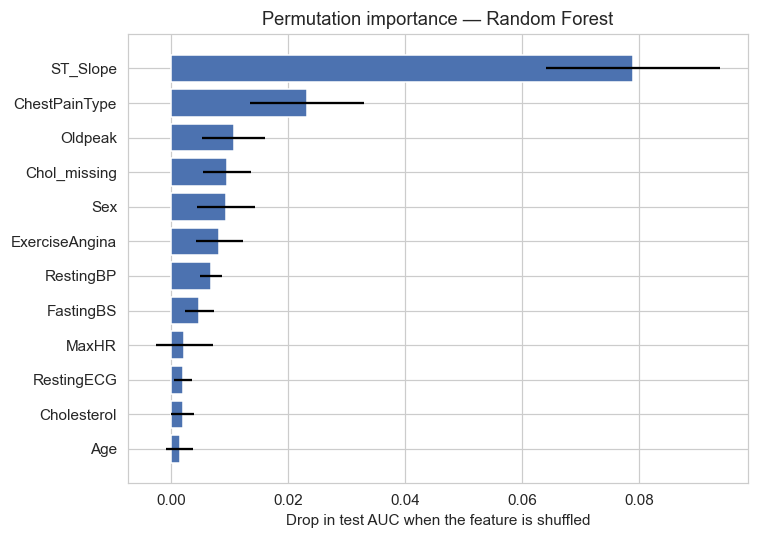

In [37]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=30,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std}, index=X_test.columns).sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"], color="#4C72B0")
ax.set_xlabel("Drop in test AUC when the feature is shuffled"); ax.set_title(f"Permutation importance — {final_name}")
plt.tight_layout(); plt.show()

In [38]:
# If the final model is linear: show coefficients and odds ratios
if hasattr(final_model.named_steps["model"], "coef_"):
    names = final_model.named_steps["prep"].get_feature_names_out()
    coefs = final_model.named_steps["model"].coef_[0]
    coef_tbl = pd.DataFrame({"coefficient": coefs, "odds_ratio": np.exp(coefs)}, index=names)
    display(coef_tbl.sort_values("coefficient", ascending=False).round(3))
    print("Numeric features are standardised: an odds ratio is per +1 standard deviation.")
else:
    print(f"{final_name} has no coefficients — see the permutation importance above.")

Random Forest has no coefficients — see the permutation importance above.


**Reading:** shuffling `ST_Slope` costs the model by far the most AUC (≈ 0.08), followed by `ChestPainType` (≈ 0.02), `Oldpeak`, `Chol_missing`, `Sex` and `ExerciseAngina` (≈ 0.01 each). This matches EDA and the χ² analysis. Features like `Age`, `Cholesterol`, `RestingECG` and `MaxHR` show almost no individual importance: their information is largely shared with the leading variables, so permuting one of them alone changes little (permutation importance understates the importance of correlated features).

⚠️ `Chol_missing` ranks among the top features. It carries real predictive signal in *this* dataset, but it reflects *where/how* patients were recorded rather than a physiological mechanism. In a different hospital, with cholesterol measured systematically, this signal would disappear. See the conclusion.

### 14.5 Performance by subgroup

In [39]:
rows = []
for sex in ["M", "F"]:
    m = (X_test["Sex"] == sex).to_numpy()
    yt, pt = y_arr[m], proba_test[m]
    rows.append({"Sex": sex, "n test": m.sum(), "% disease": yt.mean() * 100,
                 "accuracy": accuracy_score(yt, pt >= 0.5), "recall": recall_score(yt, pt >= 0.5),
                 "precision": precision_score(yt, pt >= 0.5, zero_division=0),
                 "roc_auc": roc_auc_score(yt, pt) if len(np.unique(yt)) == 2 else np.nan})
pd.DataFrame(rows).set_index("Sex").round(3)

,n test,% disease,accuracy,recall,precision,roc_auc
Sex,,,,,,
M,146,65.753,0.897,0.927,0.918,0.911
F,38,15.789,0.921,0.833,0.714,0.964


**Reading:** overall performance is similar for men and women (accuracy 0.90 vs 0.92), but **the female subgroup is tiny** — 38 patients in the test set, only 6 with the disease — so the lower recall (0.83 = 5 of 6) is based on a handful of cases and cannot be interpreted reliably. Women are also under-represented in the training data (21 %). A dedicated evaluation with more female patients is needed before using the model on them.

<a id="sec15"></a>
## 15. Packaging & pre-deployment tests  *(course step 9)*

Before any large-scale deployment, we need to be sure that the saved model behaves exactly like the validated one.

**Final refit.** Standard practice once the model and hyperparameters are validated: refit the *same* pipeline on **train + test** (all 918 labelled patients) to squeeze the most out of a small dataset. Its performance cannot be re-measured on the test set (the test patients are now in the training data), so the metrics reported above remain the evidence of quality. To keep this notebook strictly honest, we save **both** versions.

In [40]:
# (a) The validated model (trained on train only) -> its metrics are the ones reported above
joblib.dump(final_model, "heart_model_validated.joblib")

# (b) The same pipeline refitted on all labelled data (for use in production)
final_model_full = clone(final_model).fit(X, y)
joblib.dump(final_model_full, "heart_model_full_data.joblib")
print("Saved: heart_model_validated.joblib, heart_model_full_data.joblib")

Saved: heart_model_validated.joblib, heart_model_full_data.joblib


In [41]:
# ---------- Pre-deployment tests ----------
loaded = joblib.load("heart_model_validated.joblib")

# Test 1: the reloaded model gives exactly the same predictions as the in-memory one
assert np.allclose(loaded.predict_proba(X_test), final_model.predict_proba(X_test)), "Reload mismatch"
print("Test 1 OK - reloaded model reproduces the validated predictions")

# Test 2: end-to-end prediction from RAW patient data (cleaning + preprocessing + model)
def predict_patient(record: dict, model=loaded, threshold=THRESHOLD):
    row = clean_raw(pd.DataFrame([record]))[FEATURES]
    p = float(model.predict_proba(row)[0, 1])
    return {"probability": round(p, 3), "flag": int(p >= threshold)}

new_patient = {"Age": 58, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": 0,
               "FastingBS": 1, "RestingECG": "Normal", "MaxHR": 110, "ExerciseAngina": "Y",
               "Oldpeak": 2.0, "ST_Slope": "Flat"}
low_risk = {"Age": 35, "Sex": "F", "ChestPainType": "ATA", "RestingBP": 118, "Cholesterol": 190,
            "FastingBS": 0, "RestingECG": "Normal", "MaxHR": 175, "ExerciseAngina": "N",
            "Oldpeak": 0.0, "ST_Slope": "Up"}
print("Test 2 - high-risk profile:", predict_patient(new_patient))
print("Test 2 - low-risk profile :", predict_patient(low_risk))

# Test 3: robustness - missing values and unseen categories must not crash the model
robust = dict(new_patient); robust["Cholesterol"] = np.nan; robust["RestingECG"] = "UNKNOWN"
print("Test 3 - missing/unseen inputs:", predict_patient(robust))

# Test 4: probabilities are valid
probs = loaded.predict_proba(X_test)
assert probs.shape == (len(X_test), 2) and ((probs >= 0) & (probs <= 1)).all() and np.allclose(probs.sum(1), 1)
print("Test 4 OK - probabilities valid")

Test 1 OK - reloaded model reproduces the validated predictions
Test 2 - high-risk profile: {'probability': 0.988, 'flag': 1}
Test 2 - low-risk profile : {'probability': 0.012, 'flag': 0}
Test 3 - missing/unseen inputs: {'probability': 0.984, 'flag': 1}
Test 4 OK - probabilities valid


In [42]:
# Reproducibility: versions used (copy into requirements.txt)
import importlib.metadata as md_
pkgs = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "joblib"] + (["xgboost"] if HAS_XGB else [])
print(f"python=={platform.python_version()}")
for p in pkgs:
    print(f"{p}=={md_.version(p)}")

python==3.13.1
pandas==2.2.3
numpy==2.2.4
scipy==1.18.0
scikit-learn==1.9.0
matplotlib==3.10.3
seaborn==0.13.2
joblib==1.5.3


**Before production** (course: *tests before large-scale deployment*): a pilot on new, locally collected patients to detect any shift between the training data and the real population; monitoring of inputs and performance over time; clinical review of the chosen threshold; and a clear statement that the tool supports, never replaces, clinical judgement.

<a id="sec16"></a>
## 16. Conclusion & project checklist

### What we built

A complete, leakage-free pipeline — **cleaning rules → stratified split → imputation/scaling/encoding learned on train only → model comparison by repeated cross-validation → hyperparameter search → single evaluation on the test set → packaging and tests**.

### Main results

| | |
|---|---|
| Final model | Random Forest (tuned), chosen on cross-validation among models of equivalent performance |
| Test performance (n = 184) | Accuracy 0.90 · Precision 0.90 · **Recall 0.92** · F1 0.91 · **AUC 0.93** |
| 95 % bootstrap CI (AUC) | 0.89 – 0.97 |
| Baseline for comparison | Dummy: AUC 0.50 · Logistic regression: AUC 0.91 (test), 0.92 (CV) |

### Key lessons

1. **Data quality drove the result more than the algorithm.** The 172 zero cholesterol values were the main trap; handling them without leakage (train-only median + missing flag) matters more than choosing between random forest and boosting.
2. **A methodological correction to Week 2:** imputing missing values with a median grouped by the *target* uses information unavailable at prediction time; the new pipeline imputes with the train median only.
3. **Model differences are within noise.** Logistic regression, SVM and the ensembles are statistically close. If explainability is a priority, the **logistic regression** (AUC 0.91 on test, almost no overfitting, readable coefficients) is a defensible alternative to the random forest at a small cost in performance; the code can switch to it by changing one line in section 12.1.
4. **Uncertainty is real.** With 184 test patients, the 95 % interval on accuracy spans ≈ 86–94 %; anyone quoting a single accuracy value should quote the interval.

### Limitations
- Small, merged dataset: possible hospital effects, women under-represented, and a `Chol_missing` signal that reflects data collection rather than biology.
- No external validation: performance on a different population (e.g. a local Cameroonian cohort) is unknown and could be lower.
- The negative-`Oldpeak` rule (set to 0) is an assumption that should be confirmed by a clinician.
- This model is a decision-support prototype, **not** a diagnostic tool.

### Checklist of an ML project (course annex)

- [x] Problem defined and context understood
- [x] Data imported, types checked
- [x] Exploration (plots, correlations) without modifying the data
- [x] Duplicates, types, useless columns handled
- [x] Missing values diagnosed (disguised zeros; informative missingness kept as a feature)
- [x] Train / test split done **before** any learned transformation (stratified, 80/20)
- [x] Imputation computed on the train set only (inside the pipeline)
- [x] Standardisation, log transform where needed
- [x] Encoding (label / ordinal / one-hot)
- [x] Feature selection (correlation > 95 %, low variance, χ², link with target) — on train only
- [x] Simple baseline trained first, then more complex models
- [x] Cross-validation and hyperparameter optimisation (Grid / Randomized search)
- [x] Evaluation on the test set with appropriate metrics (+ confidence intervals, threshold, subgroups)
- [x] Tests before deployment (reload, end-to-end, robustness)

### Possible next steps
- External validation on a locally collected cohort (the most valuable next step).
- Probability calibration and decision-curve analysis.
- Compare with / add CatBoost; try SHAP values for per-patient explanations.
- Wrap `clean_raw` + the saved model in a small API or Streamlit app.